In [ ]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 

# answer appartement for the first input
chemin = input("Quelle est le nom du fichier que vous voulait manipuler ?\n")+".csv"
nv_chemin = chemin
def charger_propre(chemin):
    df = pd.read_csv(chemin)
    df = df.drop_duplicates()
    df = df.dropna(subset=["prix"])
    df["etage"] = df["etage"].fillna(df["etage"].median())
    df["etage"] = df["etage"].astype(int)
    df["prix_m2"] = df["prix"] / df["surface"]
    df["prix_m2"] = df["prix_m2"].round(2)
    df = df.reset_index(drop=True)
    print(f"Il reste 15 lignes ? :{len(df) == 15}")
    nv_chemin = input("Nom de votre fichier propre :")+".csv"
    df.to_csv(nv_chemin,index = False )
    return nv_chemin

nv_chemin = charger_propre(chemin)


Il reste 15 lignes ? :True


In [ ]:
def etape_explorer(nv_chemin):
    df = pd.read_csv(nv_chemin)
    print("Quel est le prix médian ?")
    print(f"Le prix median est de {df["prix"].median()} k€.")
    print("Quel quartier a le prix au m² moyen le plus élevé ? le plus bas ?")
    moyennes = df.groupby("quartier")["prix_m2"].mean()
    #print(moyennes)
    print(f"Le plus cher : {moyennes.idxmax()} ({moyennes.max():.2f} k€/m²).")
    print(f"Le moins cher : {moyennes.idxmin()} ({moyennes.min():.2f} k€/m²).")
    print("Combien d'appartements ont au moins 3 pièces et coûtent moins de 300 k€ ?")
    q3 = len(df[(df["pieces"]>= 3) & (df["prix"]<300)])
    print(f"Il y a {q3} appartements.")

etape_explorer(nv_chemin)

Quel est le prix médian ?
Le prix median est de 250.0 k€/m².
Quel quartier a le prix au m² moyen le plus élevé ? le plus bas ?
Le plus cher : Centre (5.64 k€/m²).
Le moins cher : Nord (3.33 k€/m²).
Combien d'appartements ont au moins 3 pièces et coûtent moins de 300 k€ ?
Il y a 3 appartements.


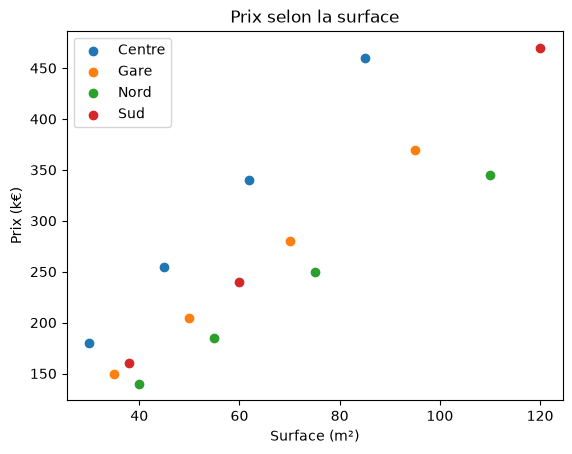

In [88]:
def visualiser(nv_chemin):
    df = pd.read_csv(nv_chemin)
    fig, ax = plt.subplots()
    for quartier, groupe in df.groupby("quartier"):
        ax.scatter(groupe["surface"], groupe["prix"], label = quartier)
    ax.set_xlabel("Surface (m²)")
    ax.set_ylabel("Prix (k€)")
    ax.set_title("Prix selon la surface")
    ax.legend()


visualiser(nv_chemin)

**Question :** Au vu du graphique, la surface suffit-elle
à expliquer le prix ?

**Réponse :** Non. Le prix augmente bien avec la surface,
mais sur le graphique, les points d'un même quartier se
regroupent : à surface égale, les appartements du Centre
sont systématiquement plus chers et ceux du Nord moins
chers. Le quartier a donc lui aussi une influence sur
le prix.

Par exemple, un appartement de 85 m² au Centre coûte
460 k€, alors qu'un appartement plus grand au Nord
(110 m²) ne coûte que 345 k€.

In [82]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error



def modeliser_surface(nv_chemin):
    df = pd.read_csv(nv_chemin)
    y = df["prix"]
    X = df[["surface"]]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)
    pred_moyenne = np.full(len(X_test), y_train.mean())
    erreur_ref = mean_absolute_error(y_test, pred_moyenne)
    m1 = LinearRegression()
    m1.fit(X_train, y_train)
    erreur_surface = mean_absolute_error(y_test, m1.predict(X_test))
    print(f"Erreur modèle moyenne : {erreur_ref:.1f} k€")
    print(f"Erreur surface seule : {erreur_surface:.1f} k€")
    return erreur_ref, erreur_surface 

erreur_ref, erreur_surface = modeliser_surface(nv_chemin)

Erreur modèle moyenne : 79.5 k€
Erreur surface seule : 48.5 k€


In [ ]:
def modeliser_quartier(nv_chemin):
    df = pd.read_csv(nv_chemin)
    y = df["prix"]
    X = pd.get_dummies(df[["surface","quartier"]], columns=["quartier"], drop_first = True, dtype = int)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

    m2 = LinearRegression()
    m2.fit(X_train, y_train)
    erreur_quartier = mean_absolute_error(y_test,m2.predict(X_test))

    print(f"Erreur surface + quartier : {erreur_quartier:.1f} k€")
    return erreur_quartier


erreur_ref, erreur_surface = modeliser_surface(nv_chemin)
erreur_quartier = modeliser_quartier(nv_chemin)



Erreur modèle moyenne : 79.5 k€
Erreur surface seule : 48.5 k€
Erreur surface + quartier : 19.5 k€


In [87]:
resultats = pd.DataFrame({
    "modele": ["Modèle moyenne", "Modèle surface seule", "Modèle surface + quartier"],
    "erreur_moyenne": [erreur_ref, erreur_surface, erreur_quartier],
}).round(1)
print(resultats)

                      modele  erreur_moyenne
0             Modèle moyenne            79.5
1       Modèle surface seule            48.5
2  Modèle surface + quartier            19.5


## Conclusion

**Résultats.** Ajouter la surface fait passer l'erreur
de 79.5 à 48.5 k€, et ajouter le quartier la fait encore
baisser à 19.5 k€. Le quartier apporte presque autant
d'information que la surface et divise l'erreur par
plus de 2.

Cela confirme ce que montrait le nuage de points :
à surface égale, un appartement du Centre coûte
nettement plus cher qu'un appartement du Nord.

**Limite.** Ces chiffres reposent sur seulement
15 appartements, dont 5 en test. Avec un autre
découpage (un autre `random_state`), les erreurs
pourraient être assez différentes. Pour une conclusion
fiable, il faudrait beaucoup plus de données.